# 02 — Exploratory Data Analysis (EDA)

## Project: Movie Recommendation System

### Objective

The objective of this notebook is to perform Exploratory Data Analysis (EDA) on the TMDB 5000 Movies dataset.

EDA helps us understand the structure, distribution, patterns, relationships, and potential issues within the dataset before applying data preprocessing and feature engineering techniques.

### Key Questions

1. Which movie genres occur most frequently?
2. How are movie ratings distributed?
3. Which movies have the highest popularity?
4. How has movie production changed over time?
5. Is there a relationship between budget and revenue?
6. Which languages are most common in the dataset?
7. What patterns can we identify from numerical features?

### Dataset

- TMDB 5000 Movies Dataset
- TMDB 5000 Credits Dataset

### Expected Outcome

By the end of this notebook, we aim to identify meaningful patterns and insights that can guide the preprocessing and feature engineering stages of our movie recommendation system.

In [1]:
import ast
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 12

## 3. Load Dataset

In this section, we load the TMDB movies and credits datasets.

The movies dataset contains information such as movie titles, genres, popularity, budget, revenue, and ratings.

The credits dataset contains information about movie cast and crew members.

We will use these datasets to explore different aspects of movie data.

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

MOVIES_PATH = DATA_DIR / "tmdb_5000_movies.csv"
CREDITS_PATH = DATA_DIR / "tmdb_5000_credits.csv"

assert MOVIES_PATH.exists(), f"Movies dataset not found: {MOVIES_PATH}"
assert CREDITS_PATH.exists(), f"Credits dataset not found: {CREDITS_PATH}"

movies_df = pd.read_csv(MOVIES_PATH)
credits_df = pd.read_csv(CREDITS_PATH)

print("Datasets loaded successfully!")
print(f"Movies dataset shape: {movies_df.shape}")
print(f"Credits dataset shape: {credits_df.shape}")

Datasets loaded successfully!
Movies dataset shape: (4803, 20)
Credits dataset shape: (4803, 4)


## 4. Dataset Overview

Before analyzing individual features, we examine the overall structure of both datasets.

This includes:
- Number of rows and columns
- Column names
- Data types
- Basic statistical information

This provides an overview of the data available for analysis.

In [3]:
print("Movies Dataset")
print("=" * 50)

display(movies_df.head())

print("\nCredits Dataset")
print("=" * 50)

display(credits_df.head())

Movies Dataset


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""name"": ""Fantasy""}, {...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"": 2964, ""name"": ""future""}, {""id"": 3386, ""name"": ""sp...",en,Avatar,"In the 22nd century, a paraplegic Marine is dispatched to the moon Pandora on a unique mission, ...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289}, {""name"": ""Twentieth Century Fox Film Corporatio...","[{""iso_3166_1"": ""US"", ""name"": ""United States of America""}, {""iso_3166_1"": ""GB"", ""name"": ""United ...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso_639_1"": ""es"", ""name"": ""Espa\u00f1ol""}]",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""name"": ""Fantasy""}, {""id"": 28, ""name"": ""Action""}]",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""name"": ""drug abuse""}, {""id"": 911, ""name"": ""exotic is...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, has come back to life and is headed to the edge of t...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""name"": ""Jerry Bruckheimer Films"", ""id"": 130}, {""na...","[{""iso_3166_1"": ""US"", ""name"": ""United States of America""}]",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adventure""}, {""id"": 80, ""name"": ""Crime""}]",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name"": ""based on novel""}, {""id"": 4289, ""name"": ""secret...",en,Spectre,A cryptic message from Bond’s past sends him on a trail to uncover a sinister organization. Whil...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""name"": ""Danjaq"", ""id"": 10761}, {""name"": ""B24"", ""id"": ...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""}, {""iso_3166_1"": ""US"", ""name"": ""United States of ...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""}, {""iso_639_1"": ""en"", ""name"": ""English""}, {""iso_639...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""name"": ""Crime""}, {""id"": 18, ""name"": ""Drama""}, {""id"": ...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853, ""name"": ""crime fighter""}, {""id"": 949, ""name"": ""te...",en,The Dark Knight Rises,"Following the death of District Attorney Harvey Dent, Batman assumes responsibility for Dent's c...",112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""name"": ""Warner Bros."", ""id"": 6194}, {""name"": ""DC E...","[{""iso_3166_1"": ""US"", ""name"": ""United States of America""}]",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adventure""}, {""id"": 878, ""name"": ""Science Fic...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"": 839, ""name"": ""mars""}, {""id"": 1456, ""name"": ""medal...",en,John Carter,"John Carter is a war-weary, former military captain who's inexplicably transported to the myster...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States of Ameri


Credits Dataset


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""credit_id"": ""5602a8a7c3a3685532001c9a"", ""gender"": ...","[{""credit_id"": ""52fe48009251416c750aca23"", ""department"": ""Editing"", ""gender"": 0, ""id"": 1721, ""jo..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Sparrow"", ""credit_id"": ""52fe4232c3a36847f800b50d"", ""g...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""department"": ""Camera"", ""gender"": 2, ""id"": 120, ""job""..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""credit_id"": ""52fe4d22c3a368484e1d8d6b"", ""gender"": 2,...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""department"": ""Sound"", ""gender"": 2, ""id"": 153, ""job"":..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Batman"", ""credit_id"": ""52fe4781c3a36847f8139869"", ""g...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""department"": ""Sound"", ""gender"": 2, ""id"": 947, ""job"":..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""credit_id"": ""52fe479ac3a36847f813ea75"", ""gender"": 2...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""department"": ""Writing"", ""gender"": 2, ""id"": 7, ""job"":..."


In [4]:
dataset_summary = pd.DataFrame(
    {
        "Dataset": ["Movies", "Credits"],
        "Rows": [movies_df.shape[0], credits_df.shape[0]],
        "Columns": [movies_df.shape[1], credits_df.shape[1]],
        "Memory (MB)": [
            movies_df.memory_usage(deep=True).sum() / (1024**2),
            credits_df.memory_usage(deep=True).sum() / (1024**2),
        ],
    }
)

display(dataset_summary.round(2))

,Dataset,Rows,Columns,Memory (MB)
0,Movies,4803,20,7.93
1,Credits,4803,4,34.34


## 5. Numerical Feature Analysis

In this section, we examine numerical columns to understand their statistical distributions.

Important numerical features include:

- Budget
- Revenue
- Popularity
- Vote Average
- Vote Count
- Runtime

We use descriptive statistics to understand the minimum, maximum, mean, median, and spread of these features.

In [5]:
numerical_columns = [
    "budget",
    "revenue",
    "popularity",
    "vote_average",
    "vote_count",
    "runtime",
]

available_numerical_columns = [
    column for column in numerical_columns if column in movies_df.columns
]

display(movies_df[available_numerical_columns].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
budget,4803.0,29045039.88,4.072239e+07,0.0,790000.00,15000000.00,40000000.00,3.800000e+08
revenue,4803.0,82260638.65,1.628571e+08,0.0,0.00,19170001.00,92917187.00,2.787965e+09
popularity,4803.0,21.49,3.182000e+01,0.0,4.67,12.92,28.31,8.755800e+02
vote_average,4803.0,6.09,1.190000e+00,0.0,5.60,6.20,6.80,1.000000e+01
vote_count,4803.0,690.22,1.234590e+03,0.0,54.00,235.00,737.00,1.375200e+04
runtime,4801.0,106.88,2.261000e+01,0.0,94.00,103.00,118.00,3.380000e+02


In [6]:
for column in available_numerical_columns:
    print(f"{column}:")
    print(f"Mean: {movies_df[column].mean():,.2f}")
    print(f"Median: {movies_df[column].median():,.2f}")
    print(f"Standard Deviation: {movies_df[column].std():,.2f}")
    print("-" * 40)

budget:
Mean: 29,045,039.88
Median: 15,000,000.00
Standard Deviation: 40,722,391.26
----------------------------------------
revenue:
Mean: 82,260,638.65
Median: 19,170,001.00
Standard Deviation: 162,857,100.94
----------------------------------------
popularity:
Mean: 21.49
Median: 12.92
Standard Deviation: 31.82
----------------------------------------
vote_average:
Mean: 6.09
Median: 6.20
Standard Deviation: 1.19
----------------------------------------
vote_count:
Mean: 690.22
Median: 235.00
Standard Deviation: 1,234.59
----------------------------------------
runtime:
Mean: 106.88
Median: 103.00
Standard Deviation: 22.61
----------------------------------------


## 6. Univariate Analysis

Univariate analysis focuses on understanding one variable at a time.

We use histograms and box plots to identify:

- Data distribution
- Skewness
- Outliers
- Concentration of values

This helps us understand the characteristics of individual numerical features.

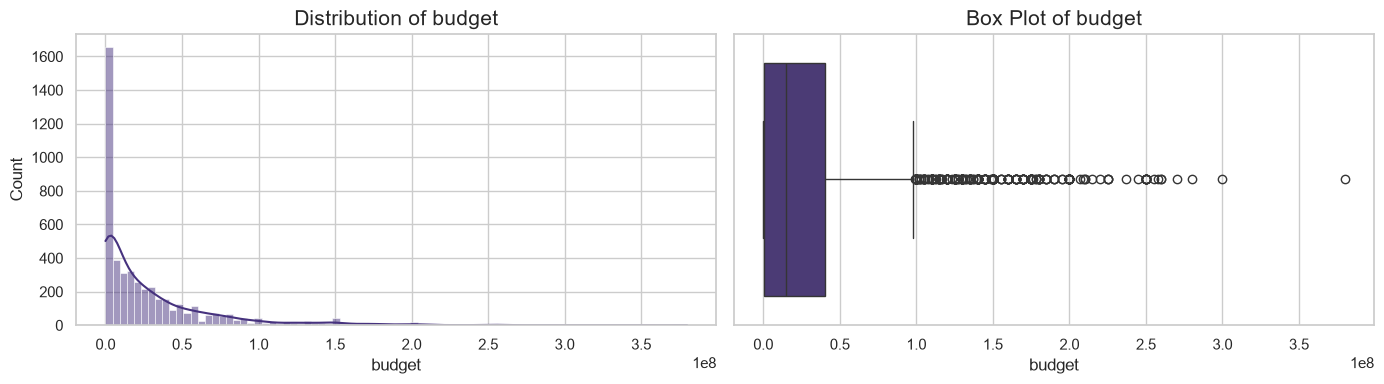

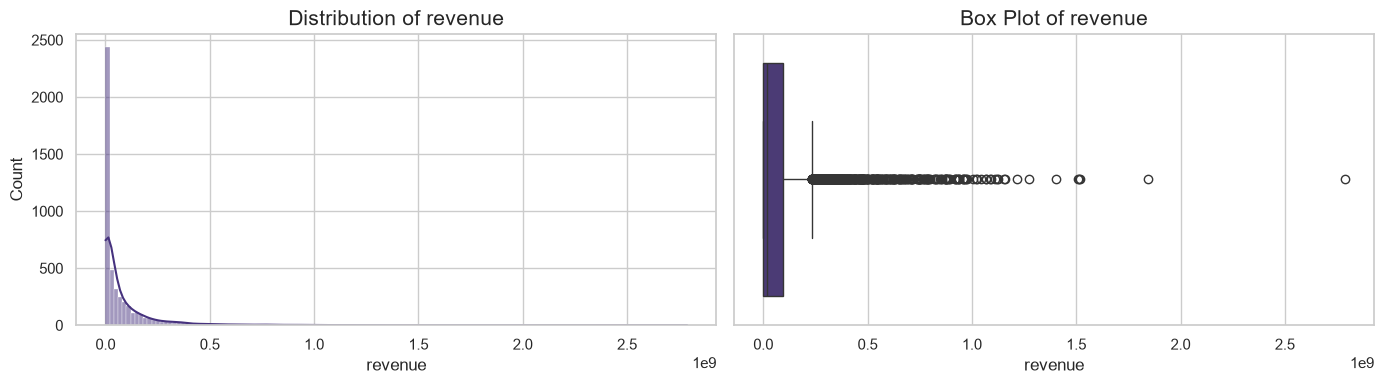

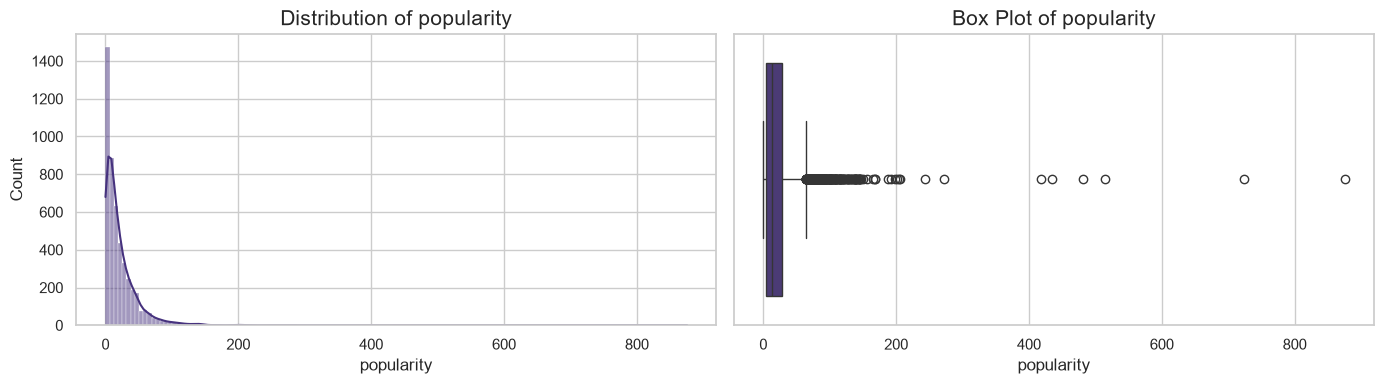

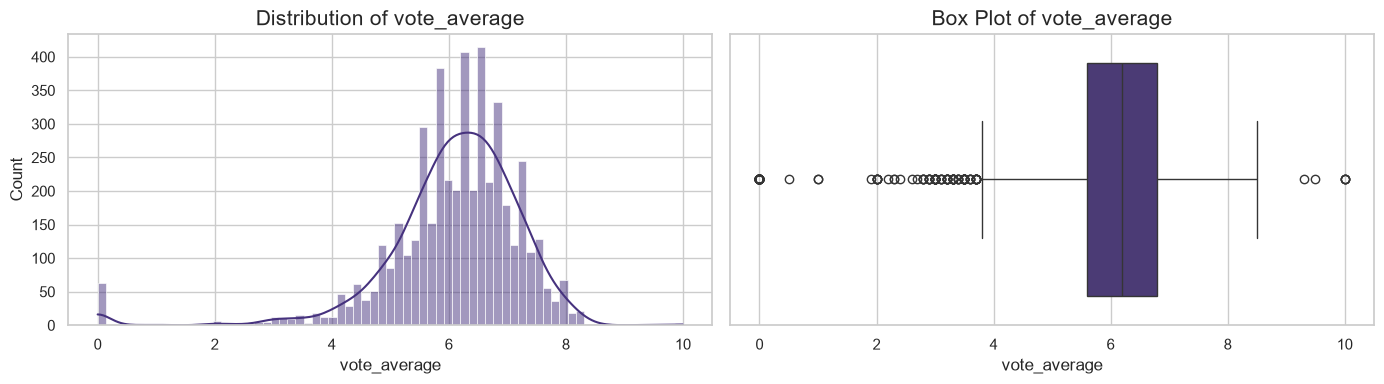

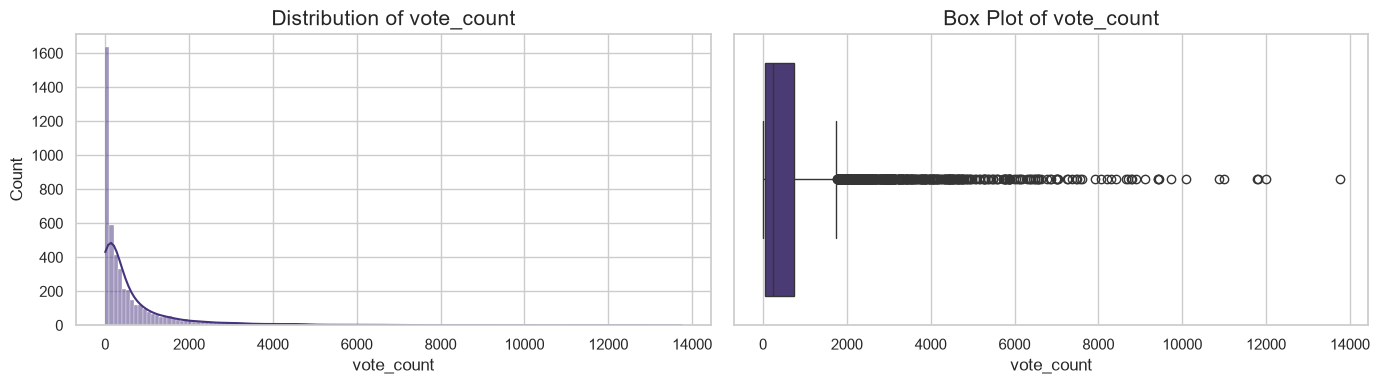

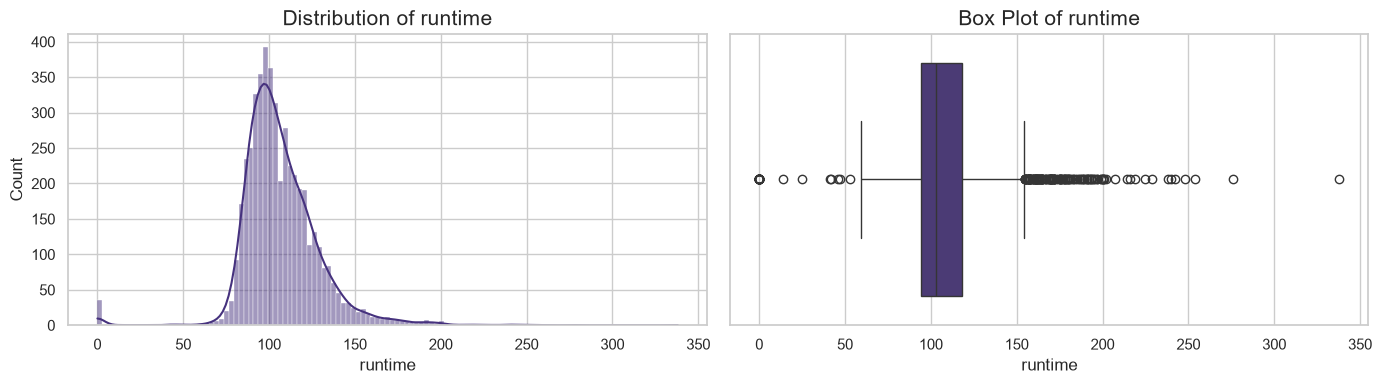

In [7]:
for column in available_numerical_columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.histplot(data=movies_df, x=column, kde=True, ax=axes[0])

    axes[0].set_title(f"Distribution of {column}")

    sns.boxplot(data=movies_df, x=column, ax=axes[1])

    axes[1].set_title(f"Box Plot of {column}")

    plt.tight_layout()
    plt.show()

### Observation

Review the histograms and box plots above.

Pay attention to:

- Whether numerical features are normally distributed or skewed.
- Whether extreme values are present.
- Whether features contain unusually large or small values.

Record observations using the actual visualizations.

## 7. Movie Ratings Analysis

Movie ratings provide information about audience opinions.

In this section, we explore:

- Distribution of average movie ratings.
- Distribution of vote counts.
- Movies with the highest average ratings.
- Movies with the highest number of votes.

This analysis helps us understand how audience ratings are distributed across the dataset.

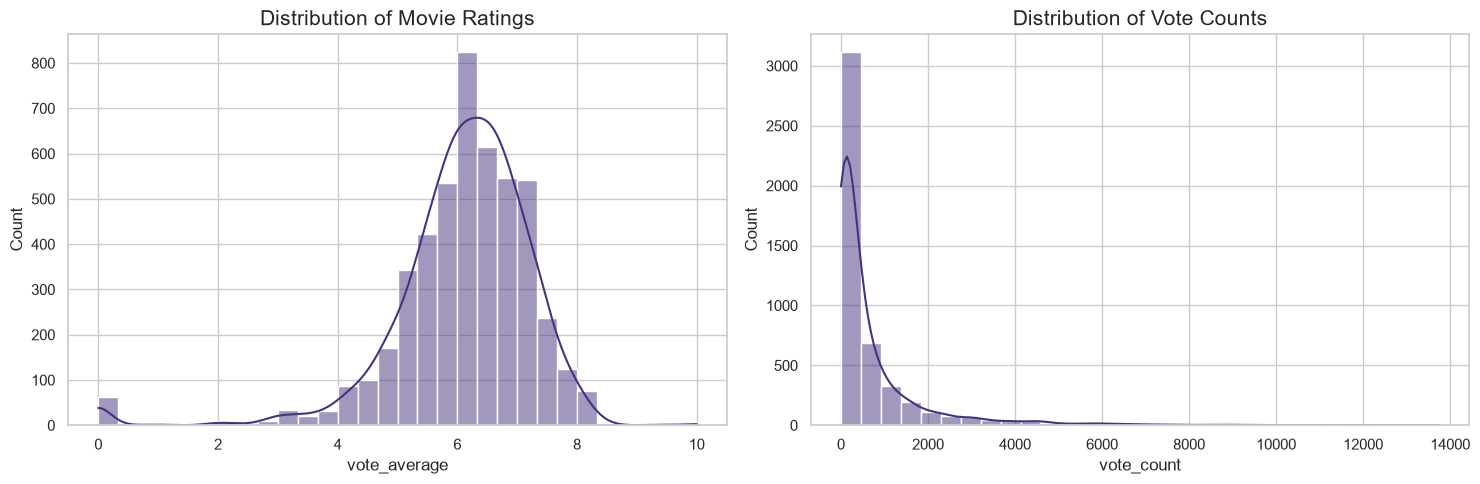

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=movies_df, x="vote_average", bins=30, kde=True, ax=axes[0])

axes[0].set_title("Distribution of Movie Ratings")

sns.histplot(data=movies_df, x="vote_count", bins=30, kde=True, ax=axes[1])

axes[1].set_title("Distribution of Vote Counts")

plt.tight_layout()
plt.show()

In [9]:
top_rated_movies = (
    movies_df[movies_df["vote_count"] >= 100]
    .sort_values(by="vote_average", ascending=False)[
        ["title", "vote_average", "vote_count"]
    ]
    .head(10)
)

display(top_rated_movies)

,title,vote_average,vote_count
1881,The Shawshank Redemption,8.5,8205
3337,The Godfather,8.4,5893
3232,Pulp Fiction,8.3,8428
2294,Spirited Away,8.3,3840
1818,Schindler's List,8.3,4329
3865,Whiplash,8.3,4254
662,Fight Club,8.3,9413
2731,The Godfather: Part II,8.3,3338
690,The Green Mile,8.2,4048
3057,American History X,8.2,3016


## 8. Genre Analysis

Genres help describe the type and category of a movie.

The genres column contains JSON-like string representations of lists of dictionaries.

For example:

[
    {"id": 28, "name": "Action"},
    {"id": 12, "name": "Adventure"}
]

We extract the genre names to understand:

- Most common genres.
- Number of movies belonging to each genre.
- Distribution of genres across the dataset.

This analysis is particularly useful for understanding the characteristics of movies that may later be used by the recommendation system.

In [10]:
def extract_names(value):
    """Extract names from a JSON-like string containing dictionaries."""

    if pd.isna(value):
        return []

    try:
        items = ast.literal_eval(value)

        if isinstance(items, list):
            return [
                item["name"]
                for item in items
                if isinstance(item, dict) and "name" in item
            ]

    except (ValueError, SyntaxError, TypeError):
        return []

    return []

In [11]:
movies_df["genre_names"] = movies_df["genres"].apply(extract_names)

genre_counts = movies_df["genre_names"].explode().dropna().value_counts()

display(genre_counts.to_frame("Movie Count"))

,Movie Count
genre_names,
Drama,2297
Comedy,1722
Thriller,1274
Action,1154
Romance,894
Adventure,790
Crime,696
Science Fiction,535
Horror,519


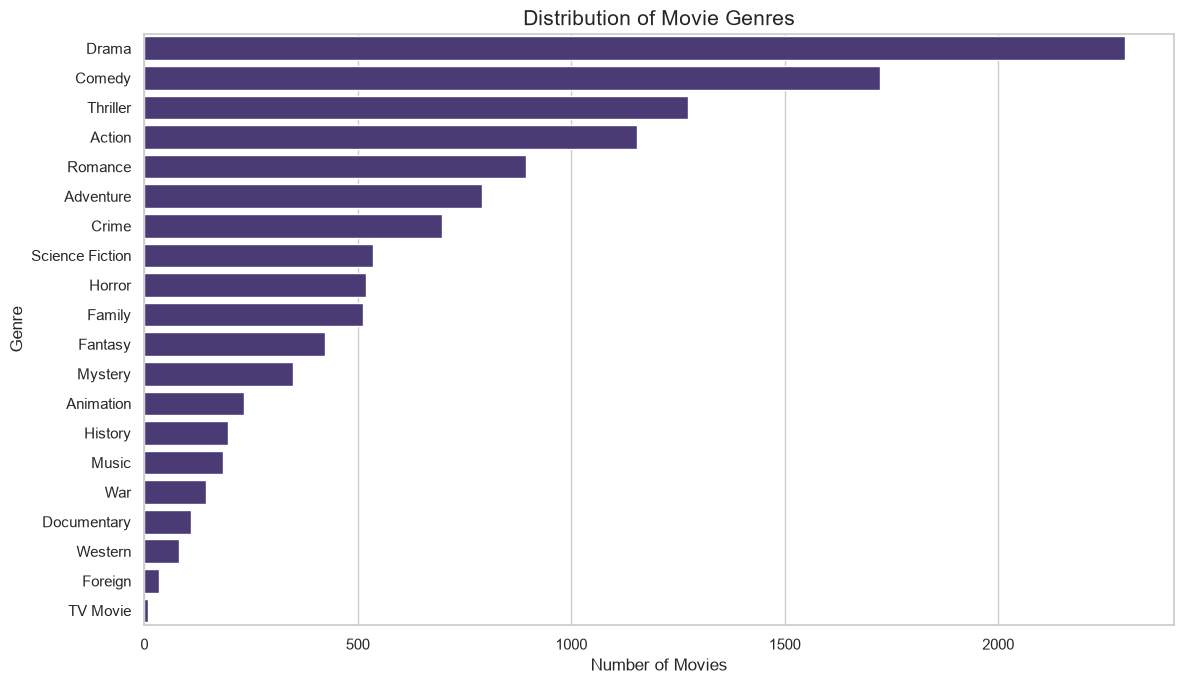

In [12]:
plt.figure(figsize=(12, 7))

sns.barplot(x=genre_counts.values, y=genre_counts.index)

plt.title("Distribution of Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

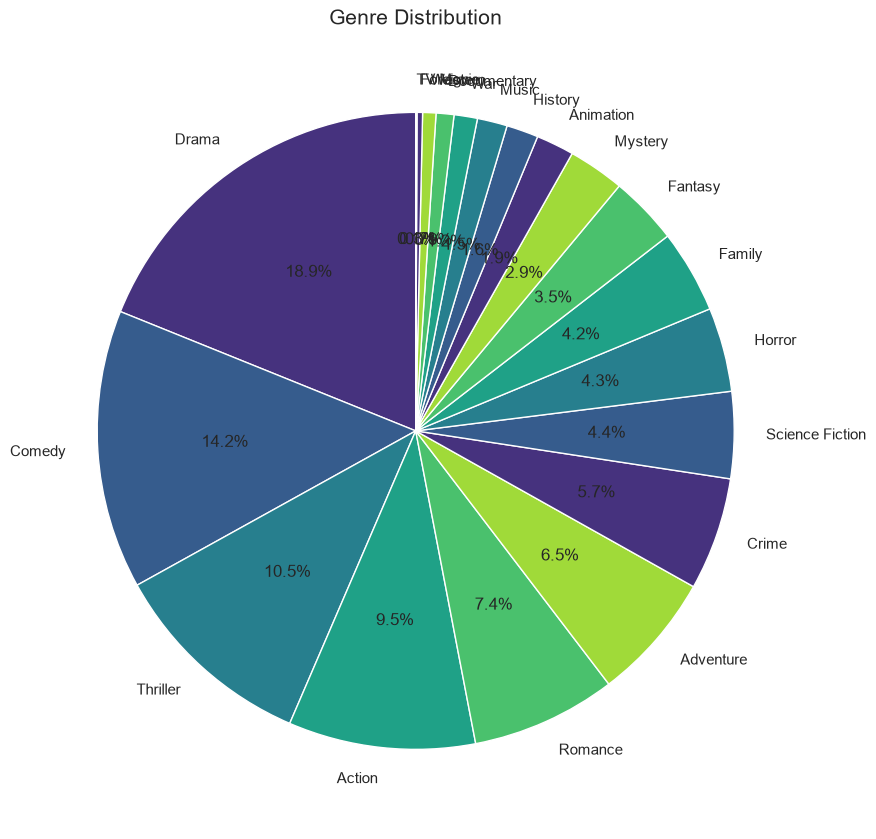

In [13]:
plt.figure(figsize=(9, 9))

genre_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)

plt.title("Genre Distribution")

plt.ylabel("")
plt.tight_layout()
plt.show()

## 9. Release Year Analysis

In this section, we analyze movie release dates to understand how movie production has changed over time.

We explore:

- Number of movies released each year.
- Years with the highest movie production.
- Trends in movie releases.

This helps identify changes in the volume of movies represented in the dataset.

In [14]:
movies_df["release_date"] = pd.to_datetime(movies_df["release_date"], errors="coerce")

movies_df["release_year"] = movies_df["release_date"].dt.year

yearly_releases = movies_df["release_year"].value_counts().sort_index()

display(yearly_releases.to_frame("Movie Count").tail(20))

,Movie Count
release_year,
1998.0,133
1999.0,171
2000.0,166
2001.0,183
2002.0,203
2003.0,169
2004.0,204
2005.0,217
2006.0,237


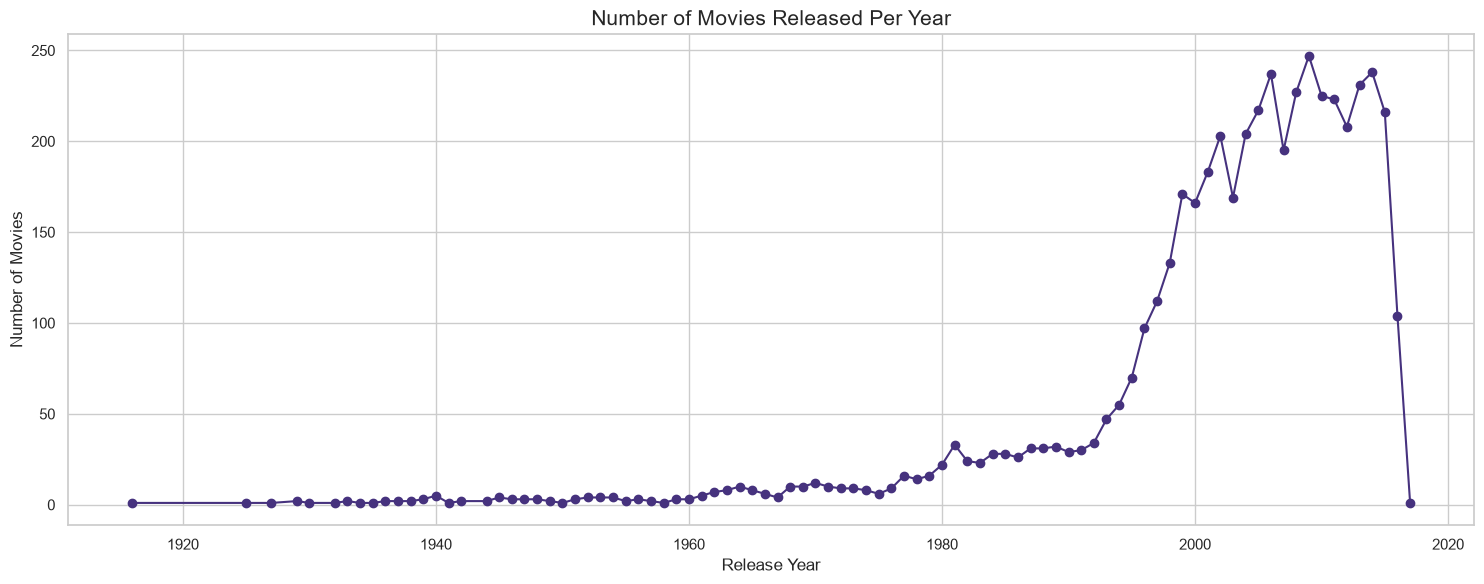

In [15]:
plt.figure(figsize=(15, 6))

yearly_releases.plot(kind="line", marker="o")

plt.title("Number of Movies Released Per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

## 10. Budget and Revenue Analysis

Budget and revenue are important financial features of movies.

In this section, we investigate:

- Distribution of movie budgets.
- Distribution of movie revenues.
- Relationship between budget and revenue.
- Movies with the highest revenue.

Zero values are examined separately because they may represent unavailable financial information rather than actual zero-cost movies.

In [16]:
financial_df = movies_df[(movies_df["budget"] > 0) & (movies_df["revenue"] > 0)].copy()

print(f"Movies with positive budget and revenue: {len(financial_df)}")

Movies with positive budget and revenue: 3229


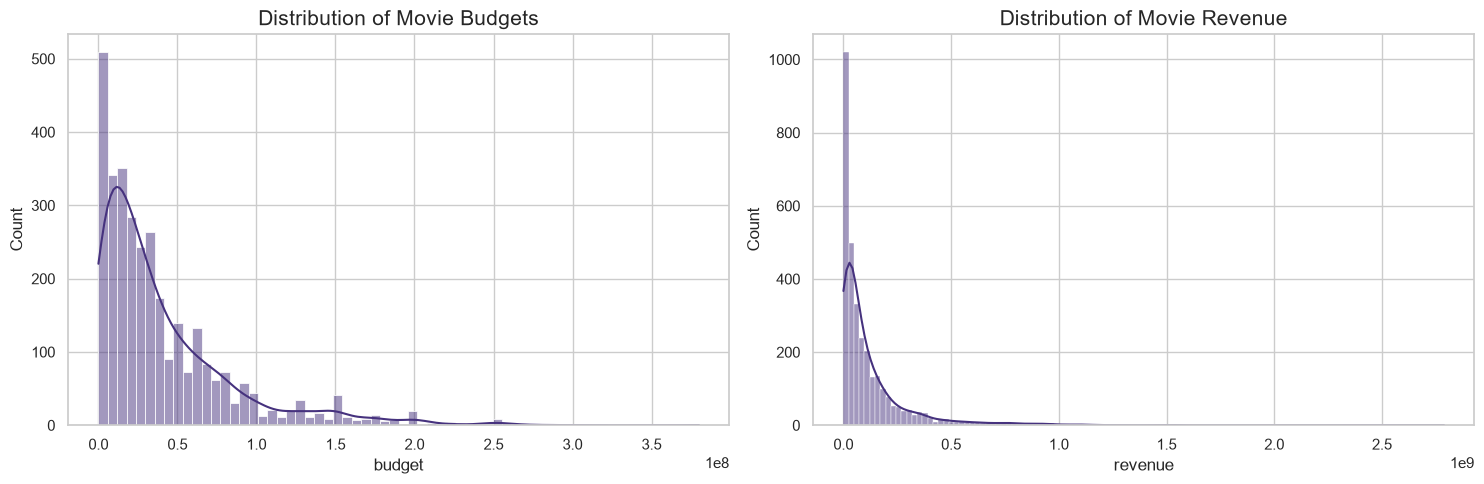

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=financial_df, x="budget", kde=True, ax=axes[0])

axes[0].set_title("Distribution of Movie Budgets")

sns.histplot(data=financial_df, x="revenue", kde=True, ax=axes[1])

axes[1].set_title("Distribution of Movie Revenue")

plt.tight_layout()
plt.show()

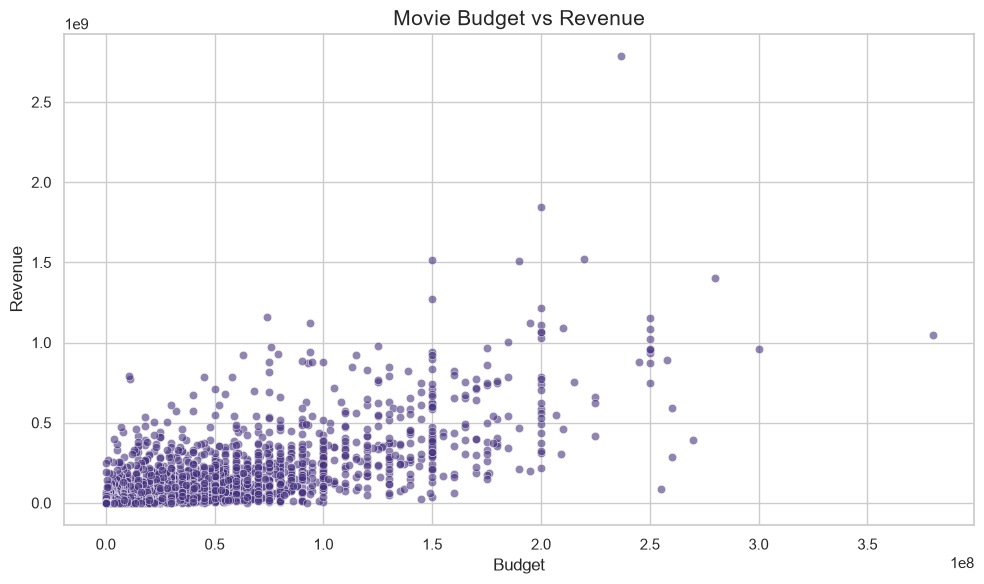

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=financial_df, x="budget", y="revenue", alpha=0.6)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

In [19]:
top_revenue_movies = financial_df.sort_values("revenue", ascending=False)[
    ["title", "budget", "revenue", "popularity"]
].head(10)

display(top_revenue_movies)

,title,budget,revenue,popularity
0,Avatar,237000000,2787965087,150.437577
25,Titanic,200000000,1845034188,100.025899
16,The Avengers,220000000,1519557910,144.448633
28,Jurassic World,150000000,1513528810,418.708552
44,Furious 7,190000000,1506249360,102.322217
7,Avengers: Age of Ultron,280000000,1405403694,134.279229
124,Frozen,150000000,1274219009,165.125366
31,Iron Man 3,200000000,1215439994,77.682080
546,Minions,74000000,1156730962,875.581305
26,Captain America: Civil War,250000000,1153304495,198.372395


## 11. Language Analysis

The original_language column represents the original language of a movie.

We analyze the distribution of languages to understand the language diversity within the dataset.

This can help identify the most frequently represented languages.

In [21]:
language_counts = movies_df["original_language"].value_counts().head(15)

display(language_counts.to_frame("Movie Count"))

,Movie Count
original_language,
en,4505
fr,70
es,32
zh,27
de,27
hi,19
ja,16
it,14
cn,12


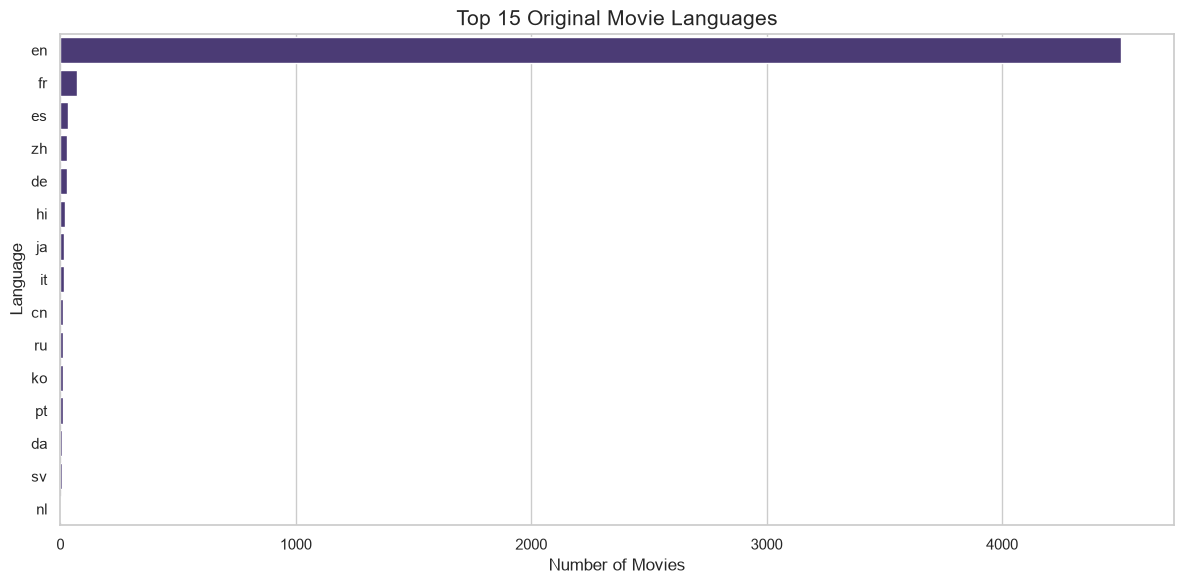

In [22]:
plt.figure(figsize=(12, 6))

sns.barplot(x=language_counts.values, y=language_counts.index)

plt.title("Top 15 Original Movie Languages")
plt.xlabel("Number of Movies")
plt.ylabel("Language")

plt.tight_layout()
plt.show()

## 12. Popularity Analysis

The popularity feature represents the popularity score provided by TMDB.

In this section, we examine:

- Distribution of popularity scores.
- Most popular movies.
- Relationship between popularity and audience ratings.

Popularity and vote_average measure different things, so they should not be treated as interchangeable.

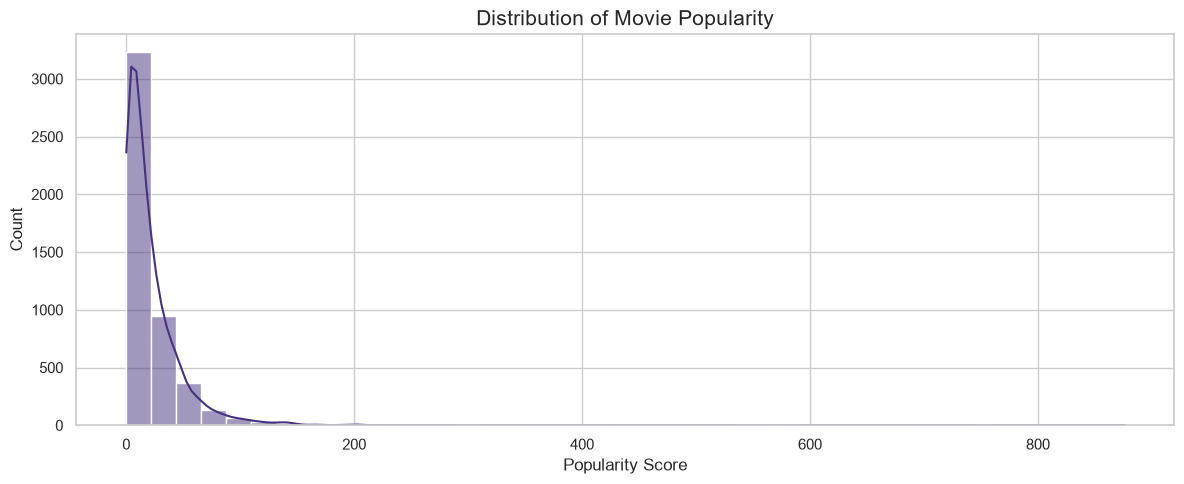

In [23]:
plt.figure(figsize=(12, 5))

sns.histplot(data=movies_df, x="popularity", bins=40, kde=True)

plt.title("Distribution of Movie Popularity")
plt.xlabel("Popularity Score")

plt.tight_layout()
plt.show()

In [24]:
top_popular_movies = movies_df.sort_values("popularity", ascending=False)[
    ["title", "popularity", "vote_average", "vote_count"]
].head(10)

display(top_popular_movies)

,title,popularity,vote_average,vote_count
546,Minions,875.581305,6.4,4571
95,Interstellar,724.247784,8.1,10867
788,Deadpool,514.569956,7.4,10995
94,Guardians of the Galaxy,481.098624,7.9,9742
127,Mad Max: Fury Road,434.278564,7.2,9427
28,Jurassic World,418.708552,6.5,8662
199,Pirates of the Caribbean: The Curse of the Black Pearl,271.972889,7.5,6985
82,Dawn of the Planet of the Apes,243.791743,7.3,4410
200,The Hunger Games: Mockingjay - Part 1,206.227151,6.6,5584
88,Big Hero 6,203.734590,7.8,6135


## 13. Correlation Analysis

Correlation analysis helps identify relationships between numerical features.

We examine the correlation between:

- Budget
- Revenue
- Popularity
- Vote Average
- Vote Count
- Runtime

A correlation coefficient ranges from -1 to +1.

- +1 indicates a strong positive linear relationship.
- -1 indicates a strong negative linear relationship.
- 0 indicates little or no linear relationship.

Correlation does not imply causation.

In [25]:
correlation_columns = [
    "budget",
    "revenue",
    "popularity",
    "vote_average",
    "vote_count",
    "runtime",
]

correlation_df = movies_df[correlation_columns].corr()

display(correlation_df.round(2))

,budget,revenue,popularity,vote_average,vote_count,runtime
budget,1.00,0.73,0.51,0.09,0.59,0.27
revenue,0.73,1.00,0.64,0.20,0.78,0.25
popularity,0.51,0.64,1.00,0.27,0.78,0.23
vote_average,0.09,0.20,0.27,1.00,0.31,0.38
vote_count,0.59,0.78,0.78,0.31,1.00,0.27
runtime,0.27,0.25,0.23,0.38,0.27,1.00


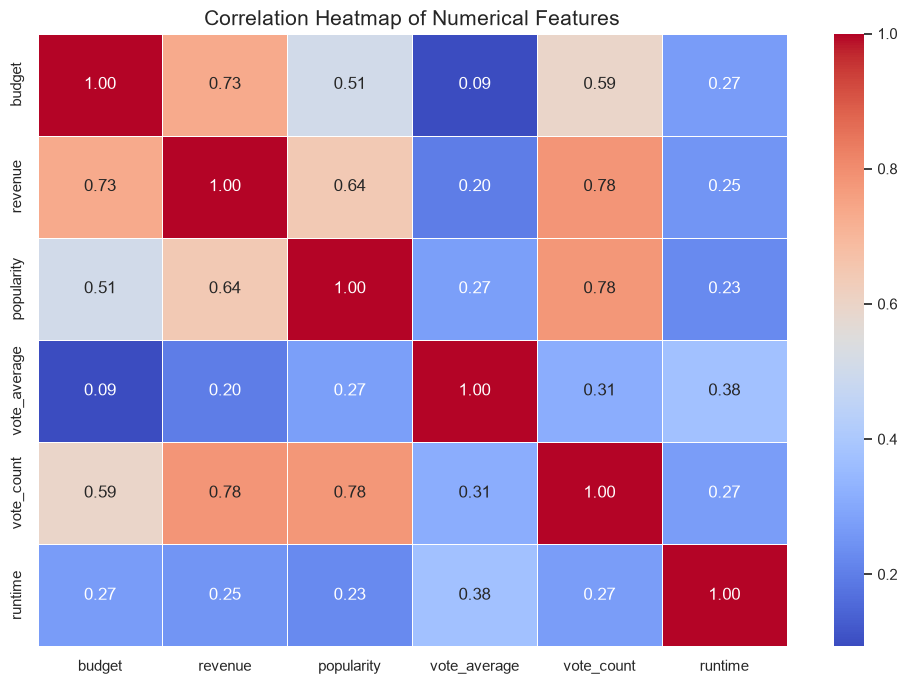

In [26]:
plt.figure(figsize=(10, 7))

sns.heatmap(correlation_df, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()

## 14. Runtime Analysis

Runtime represents the duration of a movie in minutes.

We analyze the distribution of movie runtimes and identify unusually short or long movies.

This helps us understand the typical duration of movies in the dataset.

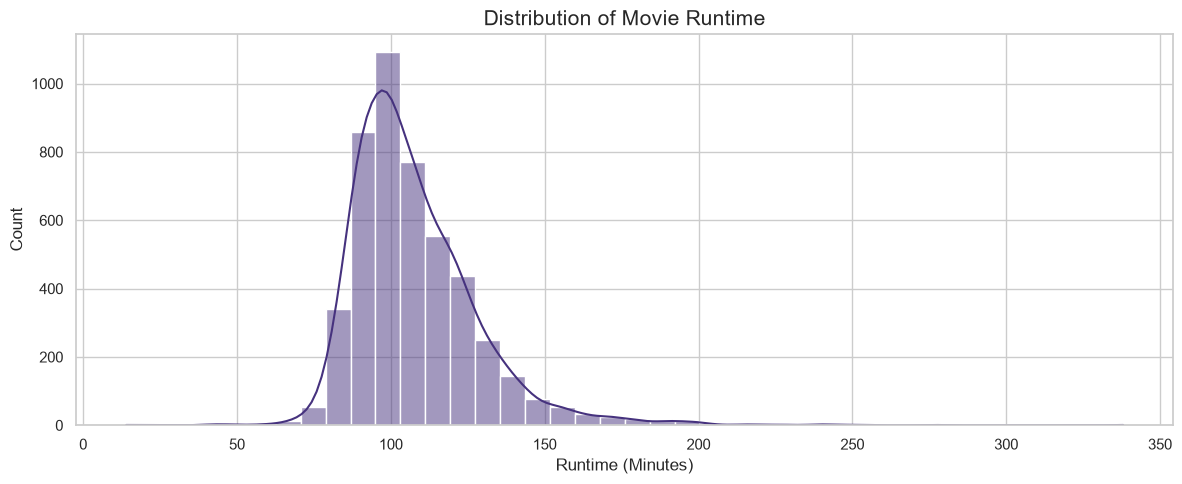

In [27]:
runtime_df = movies_df[movies_df["runtime"].notna() & (movies_df["runtime"] > 0)]

plt.figure(figsize=(12, 5))

sns.histplot(data=runtime_df, x="runtime", bins=40, kde=True)

plt.title("Distribution of Movie Runtime")
plt.xlabel("Runtime (Minutes)")

plt.tight_layout()
plt.show()

In [28]:
print("Runtime Statistics")
print("-" * 40)

print(f"Mean: {runtime_df['runtime'].mean():.2f} minutes")
print(f"Median: {runtime_df['runtime'].median():.2f} minutes")
print(f"Minimum: {runtime_df['runtime'].min():.2f} minutes")
print(f"Maximum: {runtime_df['runtime'].max():.2f} minutes")

Runtime Statistics
----------------------------------------
Mean: 107.66 minutes
Median: 104.00 minutes
Minimum: 14.00 minutes
Maximum: 338.00 minutes


## 15. Key Findings

After completing the exploratory analysis, document the most important findings.

### Dataset Observations

- Record the most frequently occurring genres.
- Identify the most common original movie language.
- Identify the distribution of movie ratings.
- Record the most common movie release periods.

### Numerical Observations

- Describe the distribution of movie budgets.
- Describe the distribution of movie revenues.
- Identify relationships between budget and revenue.
- Explain the correlation patterns between numerical features.
- Describe movie runtime distribution.

### Data Quality Observations

- Identify features containing extreme values.
- Identify numerical columns containing zero values.
- Note any unusual patterns that may require preprocessing.

### Implications for the Recommendation System

- Genres can help describe movie categories.
- Movie overview can provide textual information.
- Keywords can provide additional movie context.
- Cast and crew can contribute useful movie metadata.

These observations will guide the data preprocessing and feature engineering stages.

## 16. Conclusion

Exploratory Data Analysis provided a deeper understanding of the TMDB 5000 Movies dataset.

We explored numerical features, categorical features, movie genres, release years, ratings, popularity, financial information, and relationships between variables.

The analysis helped identify important patterns, potential outliers, and data characteristics that should be considered during preprocessing.

### Next Steps

In the next notebook, we will perform Data Preprocessing.

The focus will be on:

1. Handling missing values.
2. Identifying and handling duplicate records.
3. Processing structured JSON-like columns.
4. Cleaning relevant textual features.
5. Preparing a consistent dataset for feature engineering.

**Next Notebook:** `03_data_preprocessing.ipynb`